## Practical Genetic Algorithms
<i>by Alex Glyn-Davies</i>

This is a programming club session on practical genetic algorithms. We will cover the following:
1. Travelling Salesman Problem

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. A more realistic problem: The Travelling Salesman Problem

This is a classic problem in computer science.

Given a number of cities and pairwise distances between them, we wish find the path that visits all nodes, returning to the first node, with the <i>shortest possible distance</i>. We will call a path that visits all nodes once and returns to start a <i>tour</i>.



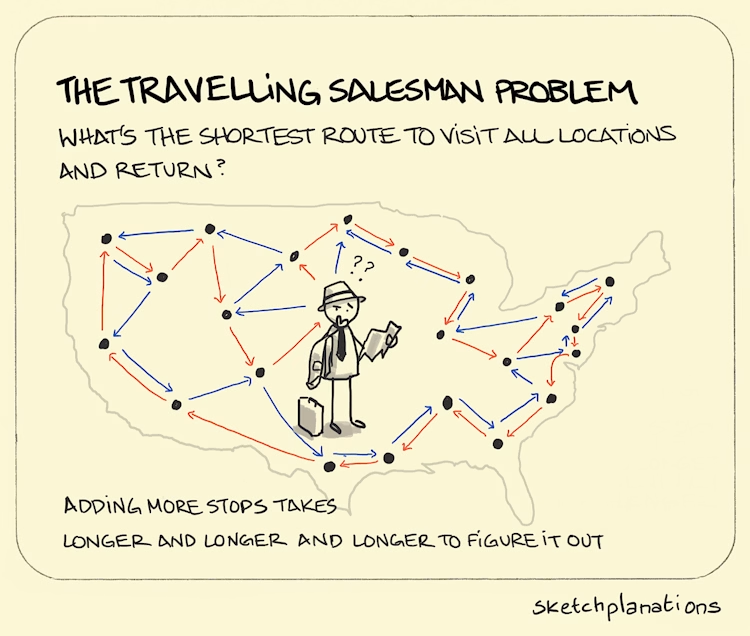

<i>Source: </i> https://sketchplanations.com/the-travelling-salesman-problem

The travelling salesman is a combinatorial problem. Given $N$ nodes, the number of possible tours is given by the number of permutations of nodes, $N!$.

If we ignore duplicates generated from cyclic rotations and reversed paths, we are left with $\frac{(N-1)!}{2}$ unique tours.

In [17]:
N = 10

# sample nodes randomly in 2D
nodes = np.random.uniform(size=(N,2))

# generate a random permutation
x = np.random.permutation(N)
print(x)
print(nodes)

[8 2 1 6 3 7 5 0 9 4]
[[0.73436398 0.41813156]
 [0.66503275 0.3950788 ]
 [0.63751545 0.3921942 ]
 [0.95911237 0.16331236]
 [0.44502828 0.04325696]
 [0.09020676 0.96523396]
 [0.75013486 0.35022144]
 [0.57386643 0.85957623]
 [0.20948922 0.26313332]
 [0.5701465  0.35856448]]


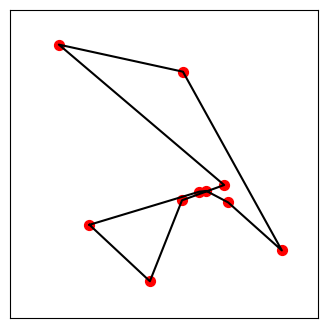

In [18]:
# we can generate the path of nodes defined by x via indexing
# and adding start node to the end
tour = np.vstack([nodes[x,:], nodes[x[0],:]])

# plotting
fig, ax = plt.subplots(figsize=(4,4))
ax.scatter(nodes[:,0], nodes[:,1], color='r', s=50)
ax.plot(tour[:,0], tour[:,1], color='k')
ax.update({'xlim':(-0.1,1.1), 'ylim':(-0.1,1.1), 'aspect':'equal', 'xticks':[], 'yticks':[]})
plt.show()

We will set the cost function to the total euclidean distance of the tour - this will provide us with a metric to select indivduals.

In [19]:
def get_tour(x, nodes):
    """ Return tour defined by x. """
    return np.vstack([nodes[x,:], nodes[x[0],:]])

def cost(x, nodes):
    """ Return total path length. """
    tour = get_tour(x, nodes)

    # difference between nodes in path
    ds = np.diff(tour, axis=0)

    # sum the euclidean norms for total path length
    tour_length = np.sum(np.linalg.norm(ds, axis=1))
    return tour_length

In [20]:
cost(x, nodes)

np.float64(3.823369515905302)

To implement a genertic algorithm for this problem, we need to redefine how we perform the <i>crossover</i> and <i>mutation</i> operations.

Say we wish to crossover a random length section of tour $x_1$ into tour $x_2$:

In [21]:
x1 = np.array([0, 4, 1, 3, 2])
x2 = np.array([2, 0, 3, 4, 1])
print('Parents')
print(x1)
print(x2)

section = np.arange(2,5)

child = x2.copy()
child[section] = x1[section]
print('Child')
print(child)

Parents
[0 4 1 3 2]
[2 0 3 4 1]
Child
[2 0 1 3 2]


This is an invalid tour of the nodes - nodes are repeated, and some are left out.

To fix this we can copy the slice from $x_1$ to the child, then fill the remaining values for the child using the order of nodes (not visited during the section from $x_1$) from the other parent tour $x_2$.

In [22]:
n = 10
x1, x2 = np.random.permutation(n), np.random.permutation(n)
print('Parents')
print(x1)
print(x2)


Parents
[5 2 8 7 1 6 9 4 0 3]
[0 9 4 7 5 1 6 8 3 2]


In [23]:

# initialise child array at arbitrary value
child = np.full(n, -1)

# randomly select section to be crossed over
start, end = sorted(np.random.choice(n, size=2, replace=False))
end = end + 1
print(f'Start: {start}, End: {end}')

Start: 0, End: 8


In [24]:
# splice in section
child[start:end] = x1[start:end]
print('Child with x1 section')
print(child)

Child with x1 section
[ 5  2  8  7  1  6  9  4 -1 -1]


In [25]:
# get positions to be filled (inverse of start:end,
# beginning from end to make fill_pos concurrent when wrapping)
fill_pos = list(range(end, n)) + list(range(0, start))
print('Positions to fill')
print(fill_pos)

Positions to fill
[8, 9]


In [26]:
# now we want the order of x2, but starting from the end of the section
print('Order of x2 starting from end of section')
x2_order = list(x2[end:]) + list(x2[:end])
print(np.array(x2_order))

Order of x2 starting from end of section
[3 2 0 9 4 7 5 1 6 8]


In [27]:
# only fill with values from x2 that do not appear in the spliced section
fill_values = [
    node for node in x2_order
    if node not in child
]

for pos, node in zip(fill_pos, fill_values):
    child[pos] = node
print('Child')
print(child)

Child
[5 2 8 7 1 6 9 4 3 0]


In [28]:
def ordered_crossover(x1, x2):
        n = len(x1)

        start, end = sorted(np.random.choice(n, size=2, replace=False))
        end = end + 1

        child = np.full(n, -1)

        child[start:end] = x1[start:end]

        fill_positions = list(range(end, n)) + list(range(0, start))
        x2_order = list(x2[end:]) + list(x2[:end])

        fill_values = [
            city for city in x2_order
            if city not in child
        ]

        for pos, city in zip(fill_positions, fill_values):
            child[pos] = city

        return child

def crossover(parents):
    children = []

    for i in range(0, len(parents) - 1, 2):
        x1 = parents[i]
        x2 = parents[i + 1]

        y1 = ordered_crossover(x1, x2)
        y2 = ordered_crossover(x2, x1)

        children.append(y1)
        children.append(y2)

    return np.array(children, dtype=int)

Mutation can performed safely by swapping two random values in x - this will ensure the mutated x is still a tour:

In [29]:
def mutate(x, mutation_rate):
    # copy to avoid overwriting parents
    x = x.copy()

    if np.random.random() < mutation_rate:
        i, j = np.random.choice(len(x), size=2, replace=False)
        x[i], x[j] = x[j], x[i]

    return x

In [30]:
print(x1)
print(mutate(x1, 1.))

[5 2 8 7 1 6 9 4 0 3]
[5 2 8 7 1 6 3 4 0 9]


Putting this all together:

In [31]:
def evolve(population, nodes, mutation_rate):
    """
    Run one generation.
    """
    costs = [cost(x, nodes) for x in population]
    order = np.argsort(costs)

    new_population = []

    # keep best two individuals - no mutation
    for i in range(2):
        new_population.append(population[order[i]].copy())

    # select parents
    parents = population[order[:population.shape[0] // 2]]

    # Create children until population is full
    while len(new_population) < population.shape[0]:
        np.random.shuffle(parents)
        children = crossover(parents)

        for child in children:
            child = mutate(child, mutation_rate)
            new_population.append(child)

            if len(new_population) == population.shape[0]:
                break

    return np.array(new_population)

In [32]:
def get_best(population, nodes):
    # return best tour and cost value in population
    costs = [cost(x, nodes) for x in population]
    i = np.argmin(costs)
    return population[i], costs[i]

In [33]:
# parameters
n_population=100
n_nodes=30
mutation_rate=0.1

# initialise
nodes = np.random.uniform(size=(n_nodes, 2))
population =np.array([
    np.random.permutation(n_nodes)
    for _ in range(n_population)
])

In [34]:
# run
generations = []
for i in range(200):
    population = evolve(population, nodes, mutation_rate)

    if i%50==0:
        out = get_best(population, nodes)
        generations.append(out)

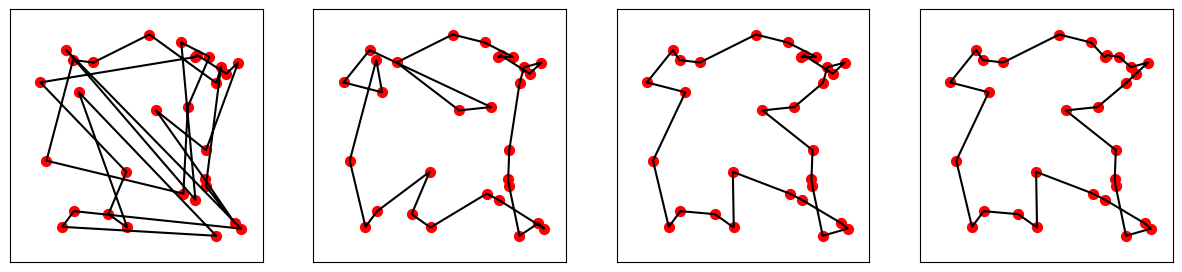

In [35]:
fig, ax = plt.subplots(1,len(generations),figsize=(15, 6))
for i, axi in enumerate(ax):
    tour = get_tour(generations[i][0], nodes)
    axi.scatter(nodes[:,0], nodes[:,1], color='r', s=50)
    axi.plot(tour[:,0], tour[:,1], color='k')
    axi.update({'xlim':(-0.1,1.1), 'ylim':(-0.1,1.1), 'aspect':'equal', 'xticks':[], 'yticks':[]})
plt.show()